In [ ]:
!pip install -q transformers datasets torchaudio librosa scikit-learn seaborn

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import torch
import librosa
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from transformers import (
    Wav2Vec2Processor,
    Wav2Vec2ForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
IESC_PATH = "/content/drive/MyDrive/Datasets/IESC_Hindi"
RAVDESS_PATH = "/content/drive/MyDrive/Datasets/RAVDESS/AudioFiles"

SAVE_PATH = "/content/drive/MyDrive/Models/Multillingual/IESC"

In [ ]:
data = []

for speaker in os.listdir(IESC_PATH):

    speaker_path = os.path.join(IESC_PATH, speaker)

    if not os.path.isdir(speaker_path):
        continue

    for session in os.listdir(speaker_path):

        session_path = os.path.join(speaker_path, session)

        if not os.path.isdir(session_path):
            continue

        for emotion in os.listdir(session_path):

            emotion_path = os.path.join(session_path, emotion)

            if not os.path.isdir(emotion_path):
                continue

            for file in os.listdir(emotion_path):

                if file.endswith(".wav"):

                    data.append({
                        "dataset":"IESC",
                        "emotion":emotion.lower(),
                        "path":os.path.join(emotion_path,file)
                    })

iesc_df = pd.DataFrame(data)
len(iesc_df)

3200

In [ ]:
ravdess_data = []

ravdess_map = {
"01":"neutral",
"03":"happy",
"04":"sad",
"05":"anger"
}

for actor in os.listdir(RAVDESS_PATH):

    actor_path = os.path.join(RAVDESS_PATH, actor)

    if not os.path.isdir(actor_path):
        continue

    for file in os.listdir(actor_path):

        parts = file.split("-")
        emotion = parts[2]

        if emotion in ravdess_map:

            ravdess_data.append({
                "dataset":"RAVDESS",
                "emotion":ravdess_map[emotion],
                "path":os.path.join(actor_path,file)
            })

ravdess_df = pd.DataFrame(ravdess_data)
len(ravdess_df)

672

In [ ]:
selected_emotions = ["anger","happy","sad","neutral"]

iesc_df = iesc_df[iesc_df["emotion"].isin(selected_emotions)]
ravdess_df = ravdess_df[ravdess_df["emotion"].isin(selected_emotions)]

print("IESC samples:",len(iesc_df))
print("RAVDESS samples:",len(ravdess_df))

IESC samples: 1600
RAVDESS samples: 672


In [ ]:
emotions = sorted(selected_emotions)

label2id = {label:i for i,label in enumerate(emotions)}
id2label = {i:label for label,i in label2id.items()}

iesc_df["label"] = iesc_df["emotion"].map(label2id)
ravdess_df["label"] = ravdess_df["emotion"].map(label2id)

In [ ]:
train_val_df, test_df = train_test_split(
    iesc_df,
    test_size=0.20,
    stratify=iesc_df["label"],
    random_state=42
)

train_df_iesc, val_df = train_test_split(
    train_val_df,
    test_size=0.125,
    stratify=train_val_df["label"],
    random_state=42
)

In [ ]:
train_df = pd.concat([ravdess_df, train_df_iesc])

In [ ]:
train_dataset = Dataset.from_pandas(train_df.reset_index(drop=True))
val_dataset = Dataset.from_pandas(val_df.reset_index(drop=True))
test_dataset = Dataset.from_pandas(test_df.reset_index(drop=True))

In [ ]:
MODEL_NAME = "facebook/wav2vec2-base"

processor = Wav2Vec2Processor.from_pretrained(MODEL_NAME)

In [ ]:
model = Wav2Vec2ForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(emotions),
    label2id=label2id,
    id2label=id2label
).to(device)

model.freeze_feature_encoder()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
project_q.weight             | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
projector.bias               | MISSING    | 
classifier.bias              | MISSING    | 
classifier.weight            | MISSING    | 
projector.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
TARGET_SAMPLING_RATE = 16000

def preprocess(batch):

    speech, sr = librosa.load(batch["path"], sr=TARGET_SAMPLING_RATE)

    batch["input_values"] = processor(
        speech,
        sampling_rate=TARGET_SAMPLING_RATE
    ).input_values[0]

    batch["labels"] = batch["label"]

    return batch

In [ ]:
train_dataset = train_dataset.map(preprocess, remove_columns=train_dataset.column_names)
val_dataset = val_dataset.map(preprocess, remove_columns=val_dataset.column_names)
test_dataset = test_dataset.map(preprocess, remove_columns=test_dataset.column_names)

train_dataset.set_format("torch")
val_dataset.set_format("torch")
test_dataset.set_format("torch")

Map:   0%|          | 0/1792 [00:00<?, ? examples/s]

Map:   0%|          | 0/160 [00:00<?, ? examples/s]

Map:   0%|          | 0/320 [00:00<?, ? examples/s]

In [ ]:
data_collator = DataCollatorWithPadding(
    tokenizer=processor,
    padding=True,
    return_tensors="pt"
)

In [ ]:
training_args = TrainingArguments(

    output_dir=SAVE_PATH,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,
    num_train_epochs=15,

    fp16=True,

    load_best_model_at_end=True,

    metric_for_best_model="accuracy",

    save_total_limit=2,

    logging_steps=50,

    report_to="none"
)

In [ ]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    preds = np.argmax(logits, axis=1)

    acc = accuracy_score(labels, preds)

    return {"accuracy": acc}

In [ ]:
trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=val_dataset,

    data_collator=data_collator,

    compute_metrics=compute_metrics,

    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,1.036090,0.833290,0.675000
2,0.653283,0.570621,0.825000
3,0.425078,0.516344,0.843750
4,0.306442,0.432731,0.900000
5,0.223777,0.556309,0.862500
6,0.123104,0.532015,0.887500
7,0.110948,0.477988,0.900000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1568, training_loss=0.4245061164303702, metrics={'train_runtime': 421.1633, 'train_samples_per_second': 63.823, 'train_steps_per_second': 7.978, 'total_flos': 4.733900006701945e+17, 'train_loss': 0.4245061164303702, 'epoch': 7.0})

In [ ]:
trainer.save_model(SAVE_PATH)

processor.save_pretrained(SAVE_PATH)

print("Model saved to:", SAVE_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/drive/MyDrive/Models/Multillingual/IESC


In [ ]:
predictions = trainer.predict(test_dataset)

y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

In [ ]:
print("\nTest Accuracy:", round(accuracy_score(y_true, y_pred)*100,2),"%")


Test Accuracy: 90.62 %


In [ ]:
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=emotions,
    digits=4
))


Classification Report:

              precision    recall  f1-score   support

       anger     0.9398    0.9750    0.9571        80
       happy     0.9853    0.8375    0.9054        80
     neutral     0.8276    0.9000    0.8623        80
         sad     0.8902    0.9125    0.9012        80

    accuracy                         0.9062       320
   macro avg     0.9107    0.9062    0.9065       320
weighted avg     0.9107    0.9062    0.9065       320



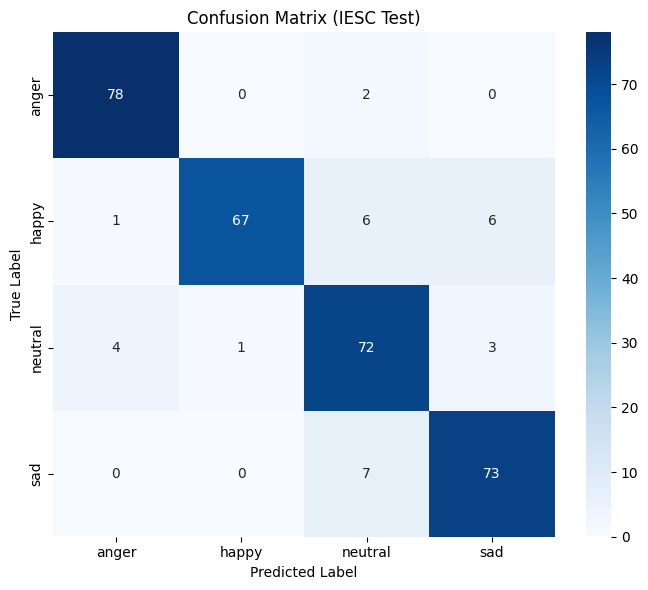

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotions,
    yticklabels=emotions
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title("Confusion Matrix (IESC Test)")

plt.tight_layout()

plt.show()